In [2]:
import os
import sys

# to setup import paths add project root dirs to sys.path
sys.path.append(os.path.join(os.getcwd(), "..", ".."))
from baseVR.base_functionality import init_import_paths
init_import_paths()

In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# %matplotlib qt
%matplotlib widget

from analytics_processing import analytics
import analytics_processing.analytics_constants as C
from CustomLogger import CustomLogger as Logger

from dashsrc.plot_components.plot_wrappers.data_selection import group_filter_data

from analytics_processing.modality_loading import session_modality_from_nas
from analytics_processing.sessions_from_nas_parsing import sessionlist_fullfnames_from_args
from analytics_processing.sessions_from_nas_parsing import fullfnames2snames

In [6]:
output_dir = "./outputs/experimental/"
data = {}
nas_dir = C.device_paths()[0]
Logger().init_logger(None, None, logging_level="WARNING")

In [7]:
animal_ids = [6]
paradigm_ids = [1100]
session_ids = None

In [8]:
session_dirs, _ = sessionlist_fullfnames_from_args(paradigm_ids, animal_ids, session_ids)
session_names = fullfnames2snames(session_dirs)

In [13]:
fr_raw = analytics.get_analytics('FiringRate40msHz', session_names=session_names)
fr = fr_raw.drop("from_ephys_timestamp", axis=1)
fr.index = fr.index.droplevel((0,1,3, ))
fr.set_index('to_ephys_timestamp', append=True, inplace=True)
fr['global_t'] = np.arange(40_000, 40_000*len(fr)+1, 40_000)
fr.set_index('global_t', append=True, inplace=True)
fr.index = fr.index.rename(['session_id', 'session_t', 'global_t'])
session_t_start = fr.index[fr.index.get_level_values('session_t') == 40_000]


In [17]:
ensembles = analytics.get_analytics('ConcatenatedEnsambleProj40ms', session_names=session_names)
ensembles.index = fr.index
ensembles.drop(["from_ephys_timestamp", "to_ephys_timestamp", 'session_id'], axis=1, inplace=True)
ensembles

/Volumes/large/BMI/VirtualReality/SpatialSequenceLearning/RUN_rYL006/rYL006_P1100/2024-11-14_15-01_rYL006_P1100_LinearTrackStop_30min/../../animal_analytics/ConcatenatedEnsambleProj40ms.parquet


Assembly001  Assembly002  \
session_id       session_t  global_t                                
2024-11-14_16-40 40000      40000           0.008793    -0.009725   
                 80000      80000           0.009878    -0.014427   
                 120000     120000          0.002362    -0.013901   
                 160000     160000          0.022914     0.052989   
                 200000     200000          0.017793     0.064332   
...                                              ...          ...   
2025-01-27_13-39 4435960000 53320480000     0.072626    -0.034628   
                 4436000000 53320520000     0.014668     0.354917   
                 4436040000 53320560000    -0.028170     0.579303   
                 4436080000 53320600000     0.102452    -0.103061   
                 4436120000 53320640000     0.031443     0.167124   

                                         Assembly003  Assembly004  \
session_id       session_t  global_t                                
2024-11-14_16-40 40000      40000          -0.273991    -0.265528   
                 80000      80000          -0.242272    -0.108817   
                 120000     120000         -0.308280    -0.462158   
                 160000     160000         -0.255557    -0.149557   
                 200000     200000         -0.260855    -0.031073   
...                                              ...          ...   
2025-01-27_13-39 4435960000 53320480000     0.199358    -0.253034   
                 4436000000 53320520000    -0.064781    -0.122191   
                 4436040000 53320560000    -0.248008    -0.199232   
                 4436080000 53320600000     0.294386    -0.101449   
                 4436120000 53320640000    -0.133559    -0.006154   

                                         Assembly005  Assembly006  \
session_id       session_t  global_t                                
2024-11-14_16-40 40000      40000           0.223767     0.184117   
                 80000      80000           0.139553    -0.085424   
                 120000     120000          0.298443     0.430169   
                 160000     160000          0.095643     0.601585   
                 200000     200000         -0.195390     0.036322   
...                                              ...          ...   
2025-01-27_13-39 4435960000 53320480000    -0.395667    -0.257848   
                 4436000000 53320520000     0.133809     0.411121   
                 4436040000 53320560000    -0.321918     0.040291   
                 4436080000 53320600000    -0.462992     1.055242   
                 4436120000 53320640000     0.034268    -0.096340   

                                         Assembly007  Assembly008  \
session_id       session_t  global_t                                
2024-11-14_16-40 40000      40000           0.150096    -0.222650   
                 80000      80000          -0.023798    -0.080344   
                 120000     120000          0.255189    -0.267318   
                 160000     160000          0.552676    -0.126625   
                 200000     200000          0.157803    -0.012087   
...                                              ...          ...   
2025-01-27_13-39 4435960000 53320480000    -0.184607     1.153548   
                 4436000000 53320520000     0.233311     0.382570   
                 4436040000 53320560000    -0.195152    -0.450052   
                 4436080000 53320600000    -0.026061    -0.260306   
                 4436120000 53320640000    -0.014381     0.185193   

                                         Assembly009  Assembly010  ...  \
session_id       session_t  global_t                               ...   
2024-11-14_16-40 40000      40000          -0.042059     0.172028  ...   
                 80000      80000           0.003309     0.197559  ...   
                 120000     120000         -0.072922     0.153246  ...   
                 160000     160000         -0.014961    -0.465266  ...   
     

In [46]:
action_enc_cols = [
    'frame_raw_500msMedian',  # rename to  forward_velocity
    'frame_raw_abs_acc_500msMedian',  # rename to  forward_acceleration
    'frame_YawPitch_abs_vel_sum_500msMedian', #  rename to off_rotation_velocity
    'frame_YawPitch_abs_acc_sum_500msMedian', #  rename to off_rotation_acceleration
 
    'head_angle_vel',       
    'head_angle',
    'movement_energy_smooth5', # rename to movement_energy
 
    'upcoming_choice',
    'reward_window',
    'lick_detected',
]
state_enc_cols = [
    'cue_visible',       
    'frame_position',
]

behavior_glm_input = analytics.get_analytics('Behavior40msAligned', session_names=session_names,
                                             columns=action_enc_cols+state_enc_cols)
behavior_glm_input.index = behavior_glm_input.index.droplevel(['paradigm_id', 'animal_id']) # drop index level
# rename
behavior_glm_input = behavior_glm_input.rename(columns={
    'frame_raw_500msMedian': 'forward_velocity',
    'frame_raw_abs_acc_500msMedian': 'forward_acceleration',
    'frame_YawPitch_abs_vel_sum_500msMedian': 'off_rotation_velocity',
    'frame_YawPitch_abs_acc_sum_500msMedian': 'off_rotation_acceleration',
    'movement_energy_smooth5': 'movement_energy',
})

print("NaN proportion per column:")
display(behavior_glm_input.isna().sum() / len(behavior_glm_input))
display(behavior_glm_input)

# use global index
behavior_glm_input.index = fr.index

# could drop rows that have at least one NaN (20 % because of pose estimation missing data)
# behavior_glm_input = behavior_glm_input.dropna()
# print("Dropping rows with NaN.  New shape:", behavior_glm_input.shape)
behavior_glm_input

NaN proportion per column:


forward_velocity             0.001626
forward_acceleration         0.001626
off_rotation_velocity        0.001626
off_rotation_acceleration    0.001626
head_angle_vel               0.157888
head_angle                   0.154718
movement_energy              0.217091
upcoming_choice              0.003418
reward_window                0.001617
lick_detected                0.001617
cue_visible                  0.001617
frame_position               0.163907
dtype: float64

forward_velocity  forward_acceleration  \
session_id       entry_id                                           
2024-11-14_16-40 0                      NaN                   NaN   
                 1                      NaN                   NaN   
                 2                      NaN                   NaN   
                 3                      NaN                   NaN   
                 4                      NaN                   NaN   
...                                     ...                   ...   
2025-01-27_13-39 110898                 NaN                   NaN   
                 110899                 NaN                   NaN   
                 110900                 NaN                   NaN   
                 110901                 NaN                   NaN   
                 110902                 NaN                   NaN   

                           off_rotation_velocity  off_rotation_acceleration  \
session_id       entry_id                                                     
2024-11-14_16-40 0                           NaN                        NaN   
                 1                           NaN                        NaN   
                 2                           NaN                        NaN   
                 3                           NaN                        NaN   
                 4                           NaN                        NaN   
...                                          ...                        ...   
2025-01-27_13-39 110898                      NaN                        NaN   
                 110899                      NaN                        NaN   
                 110900                      NaN                        NaN   
                 110901                      NaN                        NaN   
                 110902                      NaN                        NaN   

                           head_angle_vel  head_angle  movement_energy  \
session_id       entry_id                                                
2024-11-14_16-40 0                    NaN         NaN              NaN   
                 1                    NaN         NaN              NaN   
                 2                    NaN         NaN              NaN   
                 3                    NaN         NaN              NaN   
                 4                    NaN         NaN              NaN   
...                                   ...         ...              ...   
2025-01-27_13-39 110898               NaN         NaN              NaN   
                 110899               NaN         NaN              NaN   
                 110900               NaN         NaN              NaN   
                 110901               NaN         NaN              NaN   
                 110902               NaN         NaN              NaN   

                           upcoming_choice  reward_window  lick_detected  \
session_id       entry_id                                                  
2024-11-14_16-40 0                     NaN            NaN            NaN   
                 1                     NaN            NaN            NaN   
                 2                     NaN            NaN            NaN   
                 3                     NaN            NaN            NaN   
                 4                     NaN            NaN            NaN   
...                                    ...            ...            ...   
2025-01-27_13-39 110898                NaN            NaN            NaN   
                 110899                NaN            NaN            NaN   
                 110900                NaN            NaN            NaN   
                 110901                NaN            NaN            NaN   
                 110902                NaN            NaN            NaN   

                           cue_visible  frame_position  
session_id       entry_id                               
2024-11-14_16-40 0                 

forward_velocity  \
session_id       session_t  global_t                        
2024-11-14_16-40 40000      40000                     NaN   
                 80000      80000                     NaN   
                 120000     120000                    NaN   
                 160000     160000                    NaN   
                 200000     200000                    NaN   
...                                                   ...   
2025-01-27_13-39 4435960000 53320480000               NaN   
                 4436000000 53320520000               NaN   
                 4436040000 53320560000               NaN   
                 4436080000 53320600000               NaN   
                 4436120000 53320640000               NaN   

                                         forward_acceleration  \
session_id       session_t  global_t                            
2024-11-14_16-40 40000      40000                         NaN   
                 80000      80000                         NaN   
                 120000     120000                        NaN   
                 160000     160000                        NaN   
                 200000     200000                        NaN   
...                                                       ...   
2025-01-27_13-39 4435960000 53320480000                   NaN   
                 4436000000 53320520000                   NaN   
                 4436040000 53320560000                   NaN   
                 4436080000 53320600000                   NaN   
                 4436120000 53320640000                   NaN   

                                         off_rotation_velocity  \
session_id       session_t  global_t                             
2024-11-14_16-40 40000      40000                          NaN   
                 80000      80000                          NaN   
                 120000     120000                         NaN   
                 160000     160000                         NaN   
                 200000     200000                         NaN   
...                                                        ...   
2025-01-27_13-39 4435960000 53320480000                    NaN   
                 4436000000 53320520000                    NaN   
                 4436040000 53320560000                    NaN   
                 4436080000 53320600000                    NaN   
                 4436120000 53320640000                    NaN   

                                         off_rotation_acceleration  \
session_id       session_t  global_t                                 
2024-11-14_16-40 40000      40000                              NaN   
                 80000      80000                              NaN   
                 120000     120000                             NaN   
                 160000     160000                             NaN   
                 200000     200000                             NaN   
...                                                            ...   
2025-01-27_13-39 4435960000 53320480000                        NaN   
                 4436000000 53320520000                        NaN   
                 4436040000 53320560000                        NaN   
                 4436080000 53320600000                        NaN   
                 4436120000 53320640000                        NaN   

                                         head_angle_vel  head_angle  \
session_id       session_t  global_t                                  
2024-11-14_16-40 40000      40000                   NaN         NaN   
                 80000      80000                   NaN         NaN   
                 120000     120000                  NaN         NaN   
                 160000     160000                  NaN         NaN   
                 200000     200000                  NaN         NaN   
...                                                 ...         ...   
2025-01-27_13-39 4435960000 53320480000             NaN        

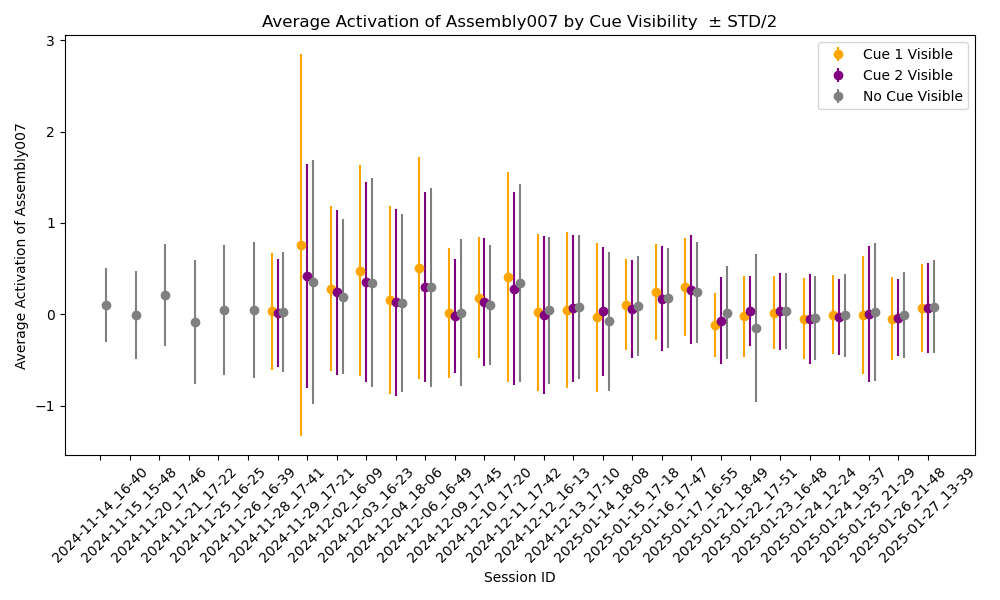

In [38]:
ens_id = 'Assembly007'
plt.close('all')

plt.figure(figsize=(10, 6))
for i, session_id in enumerate(ensembles.index.get_level_values('session_id').unique()):
    ens = ensembles.loc[session_id, ens_id]
    beh = behavior_glm_input.loc[session_id]
    
    cue1_visible = beh['cue_visible'] == 1
    cue2_visible = beh['cue_visible'] == 2
    no_cue_visible = beh['cue_visible'] == 0
    
    cue1_avg_activation = ens[cue1_visible].mean()
    cue2_avg_activation = ens[cue2_visible].mean()
    no_cue_avg_activation = ens[no_cue_visible].mean()
    
    cue1_std_activation = ens[cue1_visible].std() /2
    cue2_std_activation = ens[cue2_visible].std() /2
    no_cue_std_activation = ens[no_cue_visible].std() /2
    
    # draw at i three points with error bars
    plt.errorbar(i-0.2, cue1_avg_activation, yerr=cue1_std_activation, fmt='o', label='Cue 1 Visible' if i == 0 else "", color='orange')
    plt.errorbar(i, cue2_avg_activation, yerr=cue2_std_activation, fmt='o', label='Cue 2 Visible' if i == 0 else "", color='purple')
    plt.errorbar(i+0.2, no_cue_avg_activation, yerr=no_cue_std_activation, fmt='o', label='No Cue Visible' if i == 0 else "", color='gray')
            
plt.xticks(range(len(ensembles.index.get_level_values('session_id').unique())), ensembles.index.get_level_values('session_id').unique())
plt.xlabel('Session ID')
plt.ylabel(f'Average Activation of {ens_id}')
plt.title(f'Average Activation of {ens_id} by Cue Visibility  ± STD/2')
# rotate x labels for better visibility
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

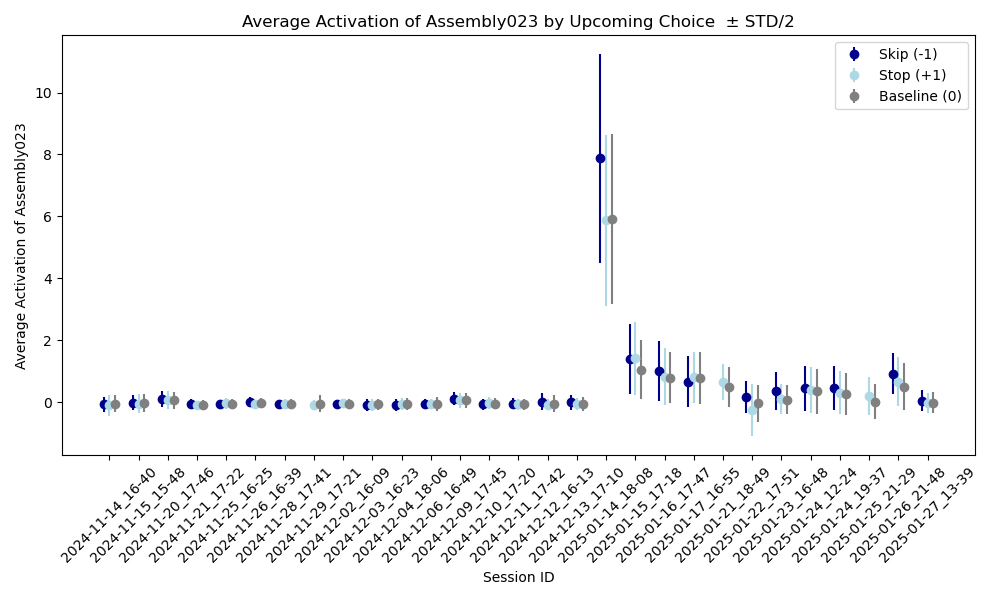

In [50]:
ens_id = 'Assembly023'
plt.close('all')

plt.figure(figsize=(10, 6))
for i, session_id in enumerate(ensembles.index.get_level_values('session_id').unique()):
    ens = ensembles.loc[session_id, ens_id]
    beh = behavior_glm_input.loc[session_id]

    # mapping: -1 -> skip, +1 -> stop, 0 -> baseline
    baseline_mask = beh['upcoming_choice'] == 0
    stop_mask = (beh['upcoming_choice'] == 1) & (beh['frame_position'] >100)
    skip_mask = (beh['upcoming_choice'] == -1) & (beh['frame_position'] >100)

    def mean_std(mask):
        if mask.sum() == 0:
            return np.nan, np.nan
        vals = ens[mask]
        return vals.mean(), vals.std() / 2

    baseline_avg, baseline_std = mean_std(baseline_mask)
    stop_avg, stop_std = mean_std(stop_mask)
    skip_avg, skip_std = mean_std(skip_mask)

    if not np.isnan(skip_avg):
        plt.errorbar(i-0.2, skip_avg, yerr=skip_std, fmt='o', label='Skip (-1)' if i == 0 else "", color='darkblue')
    if not np.isnan(stop_avg):
        plt.errorbar(i, stop_avg, yerr=stop_std, fmt='o', label='Stop (+1)' if i == 0 else "", color='lightblue')
    if not np.isnan(baseline_avg):
        plt.errorbar(i+0.2, baseline_avg, yerr=baseline_std, fmt='o', label='Baseline (0)' if i == 0 else "", color='gray')

plt.xticks(range(len(ensembles.index.get_level_values('session_id').unique())), ensembles.index.get_level_values('session_id').unique(), rotation=45)
plt.xlabel('Session ID')
plt.ylabel(f'Average Activation of {ens_id}')
plt.title(f'Average Activation of {ens_id} by Upcoming Choice  ± STD/2')
plt.legend()
plt.tight_layout()
plt.show()
